# TrafficVision AI: Traffic EDA

Explore traffic data quality, distributions, and feature relationships.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("../data")

In [2]:
# Set this to the source file when data is available.
DATA_PATH = DATA_DIR / "traffic.csv"

if DATA_PATH.exists():
    traffic = pd.read_csv(DATA_PATH)
    display(traffic.head())
else:
    traffic = pd.DataFrame()
    print(f"Add a dataset at {DATA_PATH} to begin the analysis.")

,road_id,road_name,sensor_id,timestamp,vehicle_count,avg_speed_kmph,road_capacity,congestion_level,latitude,longitude,road_length_km,traffic_density_vehicles_per_km
0,R001,NH16,S001,2026-08-25 06:00:00,37,42.9,120,Low,17.6868,83.2185,5.0,7.4
1,R001,NH16,S001,2026-08-25 06:10:00,39,47.2,120,Low,17.6868,83.2185,5.0,7.8
2,R001,NH16,S001,2026-08-25 06:20:00,26,46.1,120,Low,17.6868,83.2185,5.0,5.2
3,R001,NH16,S001,2026-08-25 06:30:00,52,40.8,120,Low,17.6868,83.2185,5.0,10.4
4,R001,NH16,S001,2026-08-25 06:40:00,23,49.3,120,Low,17.6868,83.2185,5.0,4.6


In [3]:
print("Dataset shape:", traffic.shape)

print("\nColumns:")
print(traffic.columns.tolist())

print("\nData types:")
print(traffic.dtypes)

Dataset shape: (1446, 12)

Columns:
['road_id', 'road_name', 'sensor_id', 'timestamp', 'vehicle_count', 'avg_speed_kmph', 'road_capacity', 'congestion_level', 'latitude', 'longitude', 'road_length_km', 'traffic_density_vehicles_per_km']

Data types:
road_id                                str
road_name                              str
sensor_id                              str
timestamp                              str
vehicle_count                        int64
avg_speed_kmph                     float64
road_capacity                        int64
congestion_level                       str
latitude                           float64
longitude                          float64
road_length_km                     float64
traffic_density_vehicles_per_km    float64
dtype: object


In [4]:
print("Missing values:")
print(traffic.isnull().sum())

Missing values:
road_id                            0
road_name                          0
sensor_id                          0
timestamp                          0
vehicle_count                      0
avg_speed_kmph                     0
road_capacity                      0
congestion_level                   0
latitude                           0
longitude                          0
road_length_km                     0
traffic_density_vehicles_per_km    0
dtype: int64


In [5]:
print("Duplicate rows:", traffic.duplicated().sum())


Duplicate rows: 0


In [6]:
traffic.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
road_id,1446,6,R001,241,NaN,NaN,NaN,NaN,NaN,NaN,NaN
road_name,1446,6,NH16,241,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sensor_id,1446,6,S001,241,NaN,NaN,NaN,NaN,NaN,NaN,NaN
timestamp,1446,241,2026-08-25 06:00:00,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vehicle_count,1446.0,NaN,NaN,NaN,50.104426,26.075101,1.0,28.0,49.0,71.0,123.0
avg_speed_kmph,1446.0,NaN,NaN,NaN,36.056362,10.046514,10.3,28.0,36.4,44.0,61.5
road_capacity,1446.0,NaN,NaN,NaN,100.0,12.914411,80.0,90.0,100.0,110.0,120.0
congestion_level,1446,4,Low,747,NaN,NaN,NaN,NaN,NaN,NaN,NaN
latitude,1446.0,NaN,NaN,NaN,17.714517,0.021776,17.686,17.6868,17.71855,17.738,17.7392
longitude,1446.0,NaN,NaN,NaN,83.259967,0.045215,83.2088,83.2185,83.25425,83.3013,83.3227


In [7]:
print(traffic["congestion_level"].value_counts())

print("\nPercentage:")
print(
    traffic["congestion_level"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

congestion_level
Low       747
Medium    496
High      184
Severe     19
Name: count, dtype: int64

Percentage:
congestion_level
Low       51.66
Medium    34.30
High      12.72
Severe     1.31
Name: proportion, dtype: float64


In [8]:
traffic["timestamp"] = pd.to_datetime(traffic["timestamp"])

print(traffic["timestamp"].min())
print(traffic["timestamp"].max())

2026-08-25 06:00:00
2026-08-26 22:00:00


In [9]:
traffic["hour"] = traffic["timestamp"].dt.hour

hourly_traffic = (
    traffic.groupby("hour")["vehicle_count"]
    .mean()
)

hourly_traffic

hour
0     22.444444
1     23.777778
2     21.611111
3     23.416667
4     26.666667
5     26.333333
6     27.555556
7     23.986111
8     78.944444
9     76.875000
10    78.430556
11    48.277778
12    47.027778
13    47.513889
14    47.444444
15    48.180556
16    49.777778
17    80.388889
18    74.458333
19    78.041667
20    77.666667
21    22.500000
22    24.928571
23    25.055556
Name: vehicle_count, dtype: float64

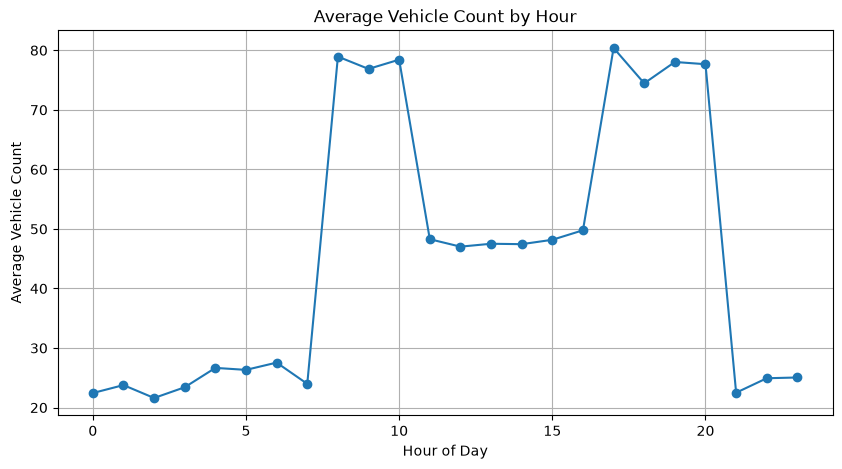

In [10]:
hourly_traffic.plot(
    kind="line",
    figsize=(10, 5),
    marker="o",
    title="Average Vehicle Count by Hour"
)

plt.xlabel("Hour of Day")
plt.ylabel("Average Vehicle Count")
plt.grid(True)
plt.show()

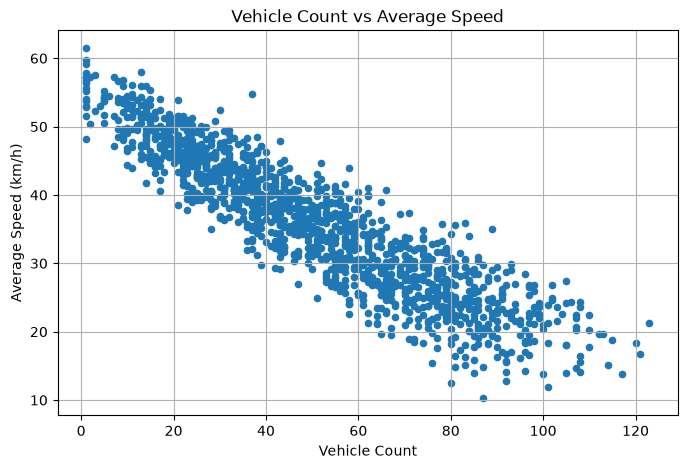

In [11]:
traffic.plot(
    x="vehicle_count",
    y="avg_speed_kmph",
    kind="scatter",
    figsize=(8, 5),
    title="Vehicle Count vs Average Speed"
)

plt.xlabel("Vehicle Count")
plt.ylabel("Average Speed (km/h)")
plt.grid(True)
plt.show()

In [12]:
traffic.groupby("congestion_level")[
    ["vehicle_count", "avg_speed_kmph", "road_capacity"]
].mean().round(2)

,vehicle_count,avg_speed_kmph,road_capacity
congestion_level,,,
High,87.57,21.94,99.46
Low,29.30,43.90,99.85
Medium,65.70,30.27,100.62
Severe,98.26,15.27,94.74


In [13]:
traffic["traffic_density"] = (
    traffic["vehicle_count"] / traffic["road_capacity"]
)

In [14]:
traffic["traffic_density"].describe()

count    1446.000000
mean        0.501502
std         0.252481
min         0.008333
25%         0.290909
50%         0.481818
75%         0.710000
max         1.087500
Name: traffic_density, dtype: float64

In [15]:
traffic.groupby("congestion_level")["traffic_density"].mean().round(3)

congestion_level
High      0.881
Low       0.294
Medium    0.653
Severe    1.038
Name: traffic_density, dtype: float64

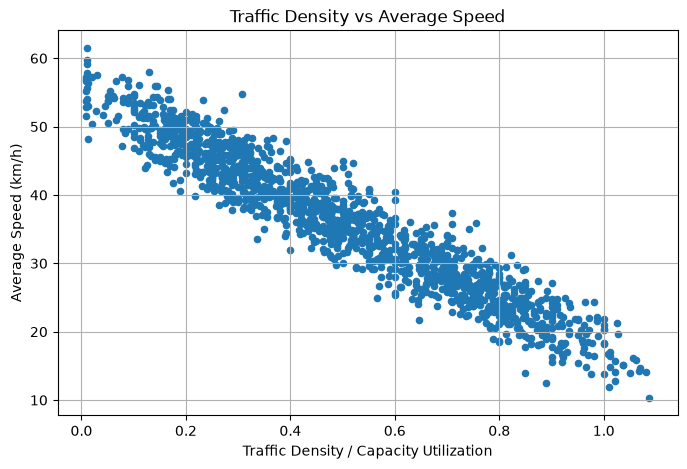

In [16]:
traffic.plot(
    x="traffic_density",
    y="avg_speed_kmph",
    kind="scatter",
    figsize=(8, 5),
    title="Traffic Density vs Average Speed"
)

plt.xlabel("Traffic Density / Capacity Utilization")
plt.ylabel("Average Speed (km/h)")
plt.grid(True)
plt.show()

In [17]:
traffic.groupby("congestion_level")[
    ["vehicle_count", "avg_speed_kmph", "traffic_density"]
].mean().round(3)

,vehicle_count,avg_speed_kmph,traffic_density
congestion_level,,,
High,87.565,21.938,0.881
Low,29.297,43.903,0.294
Medium,65.700,30.272,0.653
Severe,98.263,15.274,1.038


In [18]:
road_summary = (
    traffic.groupby("road_name")
    .agg(
        avg_vehicle_count=("vehicle_count", "mean"),
        avg_speed=("avg_speed_kmph", "mean"),
        avg_density=("traffic_density", "mean")
    )
    .sort_values("avg_vehicle_count", ascending=False)
)

road_summary

,avg_vehicle_count,avg_speed,avg_density
road_name,,,
NH16,60.107884,36.022407,0.500899
Gajuwaka Main Road,54.771784,36.366390,0.497925
MVP Double Road,49.912863,36.251867,0.499129
NAD Junction Road,49.124481,36.517427,0.491245
Beach Road,46.120332,35.573859,0.512448
Akkayyapalem Road,40.589212,35.606224,0.507365


In [ ]:
if not traffic.empty:
    display(traffic.info())
    display(traffic.describe(include="all").T)
    traffic.hist(figsize=(12, 8))
    plt.tight_layout()
    plt.show()